# 02 — EDA dan Analisis Pertanyaan Bisnis: Airbnb NYC

Notebook ini menjelajahi data bersih dari `01_airbnb_data_preparation.ipynb`: distribusi kolom numerik, tiga jenis korelasi, lalu menjawab empat pertanyaan bisnis. Semua gambar disimpan di `docs/img/`.

- **Input:** `airbnb_cleaned_for_dashboard.csv` (hasil notebook 01; jalankan notebook 01 lebih dulu)
- **Output:** gambar di `docs/img/`

**Pertanyaan bisnis:**
1. Apakah instant booking dan kebijakan pembatalan yang fleksibel berkaitan dengan tingginya aktivitas review?
2. Bagaimana hubungan harga sewa dan demand di berbagai wilayah? Wilayah mana yang paling potensial untuk ekspansi host baru?
3. Faktor apa yang paling memengaruhi tingginya rating? Apakah host terverifikasi mendapat rating lebih tinggi?
4. Apakah host dengan banyak properti punya rating dan aktivitas review yang lebih baik daripada host dengan satu properti?

## 1. Setup dan memuat data

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as ss
import seaborn as sns
from scipy.stats import norm

IN_FILE = "airbnb_cleaned_for_dashboard.csv"
IMG_DIR = os.path.join("docs", "img")
os.makedirs(IMG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")

df = pd.read_csv(IN_FILE, parse_dates=["last_review"], low_memory=False)
print(df.shape)
df.head()

(102045, 30)


,id,name,host_id,host_identity_verified,host_name,neighbourhood_group,neighbourhood,lat,long,country,...,reviews_per_month,review_rate_number,calculated_host_listings_count,availability_365,house_rules,price_category,host_type,stay_length_category,review_activity,has_house_rules
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,0.21,4,6,286,Clean up and treat the home the way you'd like...,Business-Class,Multi Host,Monthly Stay,Low,Yes
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,0.38,4,2,228,Pet friendly but please confirm with me if the...,Budget,Dual Host,Monthly Stay,Medium,Yes
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,unconfirmed,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,0.00,5,1,352,"I encourage you to use my kitchen, cooking and...",Business-Class,Single Host,Short Stay,No Review,Yes
3,1002755,Anonymous,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,4.64,4,1,322,No Special Rules,Standard,Single Host,Monthly Stay,High,No
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,0.10,3,1,289,"Please no smoking in the house, porch or on th...",Standard,Single Host,Monthly Stay,Low,Yes


In [2]:
NUM_COLS = ["construction_year", "price", "service_fee", "minimum_nights",
            "number_of_reviews", "reviews_per_month", "review_rate_number",
            "calculated_host_listings_count", "availability_365"]

CAT_COLS = ["host_identity_verified", "neighbourhood_group", "neighbourhood",
            "instant_bookable", "cancellation_policy", "room_type",
            "price_category", "stay_length_category", "host_type"]

## 2. Distribusi kolom numerik

Histogram dibandingkan dengan kurva normal (garis hitam) dari rata-rata dan simpangan baku yang sama. Kalau bentuknya jauh dari kurva, kolom itu tidak terdistribusi normal.

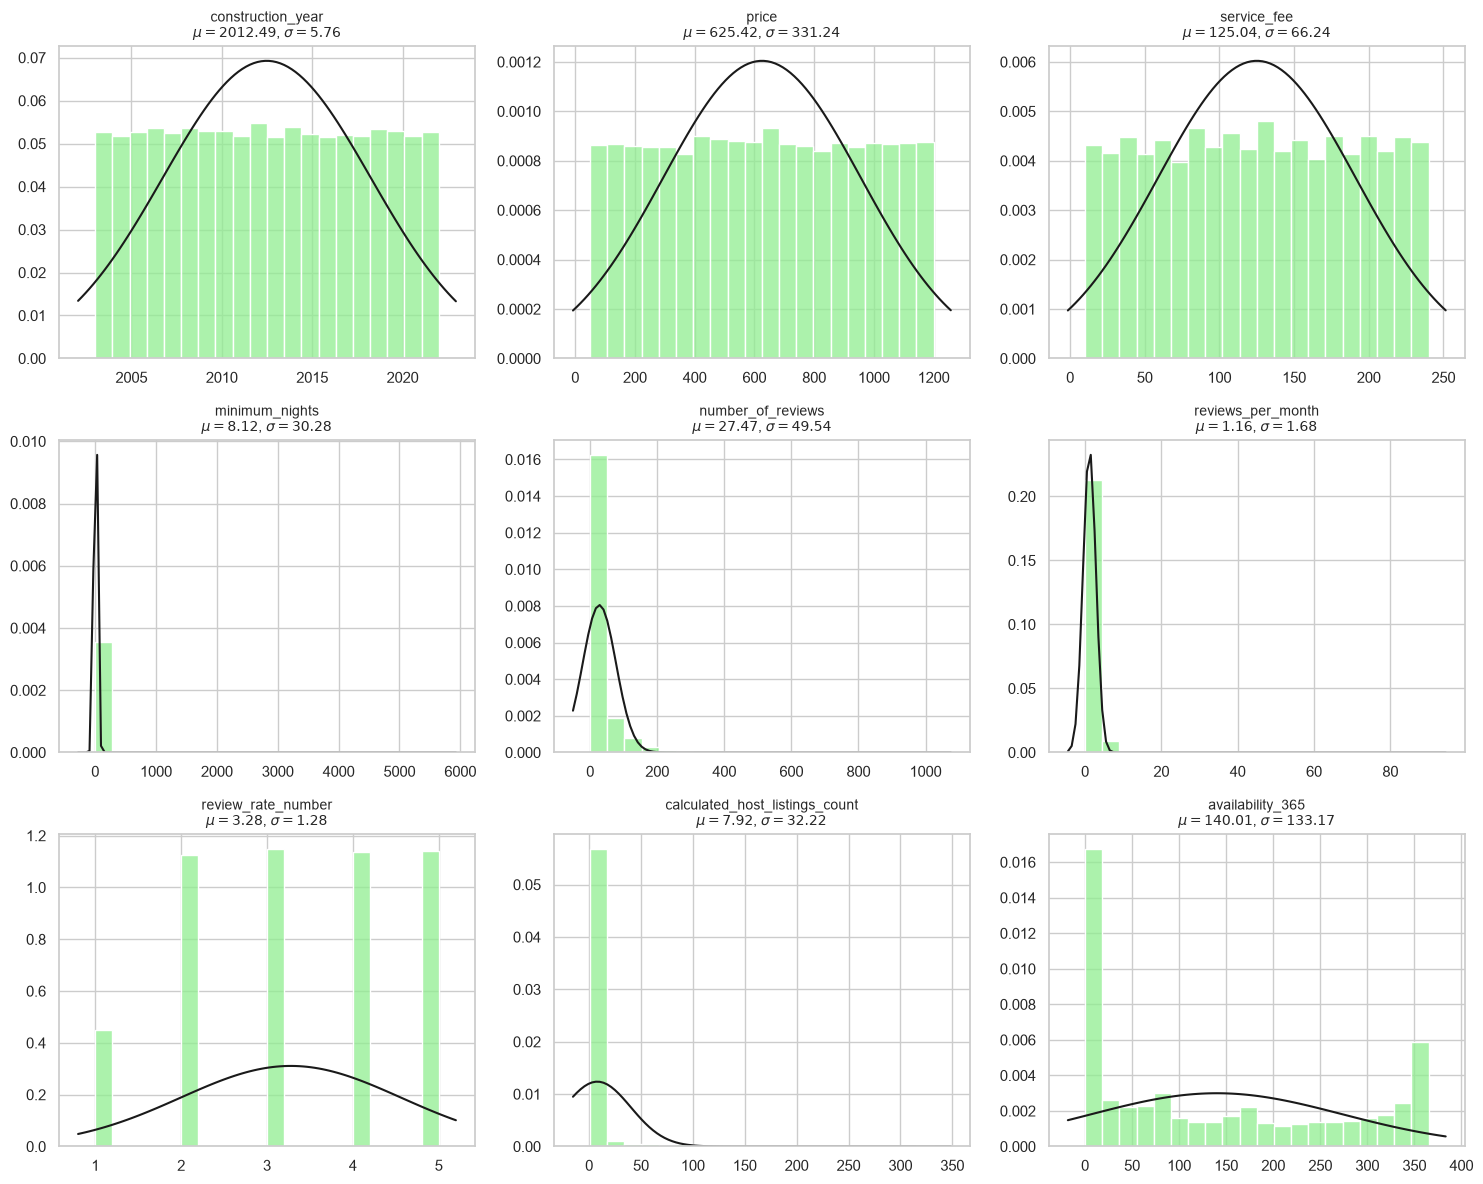

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, col in zip(axes, NUM_COLS):
    data = df[col].dropna()
    mu, std = norm.fit(data)

    sns.histplot(data, bins=20, color="lightgreen", stat="density", ax=ax, edgecolor="white")
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    ax.plot(x, norm.pdf(x, mu, std), "k", linewidth=1.5)

    ax.set_title(f"{col}\n$\\mu={mu:.2f}$, $\\sigma={std:.2f}$", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "01_distribusi_numerik.png"), dpi=150, bbox_inches="tight")
plt.show()

**Temuan:**
- `price` dan `service_fee` tersebar relatif merata (mendekati seragam): variasi harga sangat luas dan tidak ada satu titik harga yang mendominasi.
- `minimum_nights`, `number_of_reviews`, dan `calculated_host_listings_count` condong ke kanan: sebagian besar nilainya kecil dengan ekor panjang ke nilai besar.
- Hampir seluruh metrik bisnis tidak terdistribusi normal, sehingga korelasi memakai Spearman (berbasis peringkat), bukan Pearson.

## 3. Korelasi antar kolom numerik (Spearman)

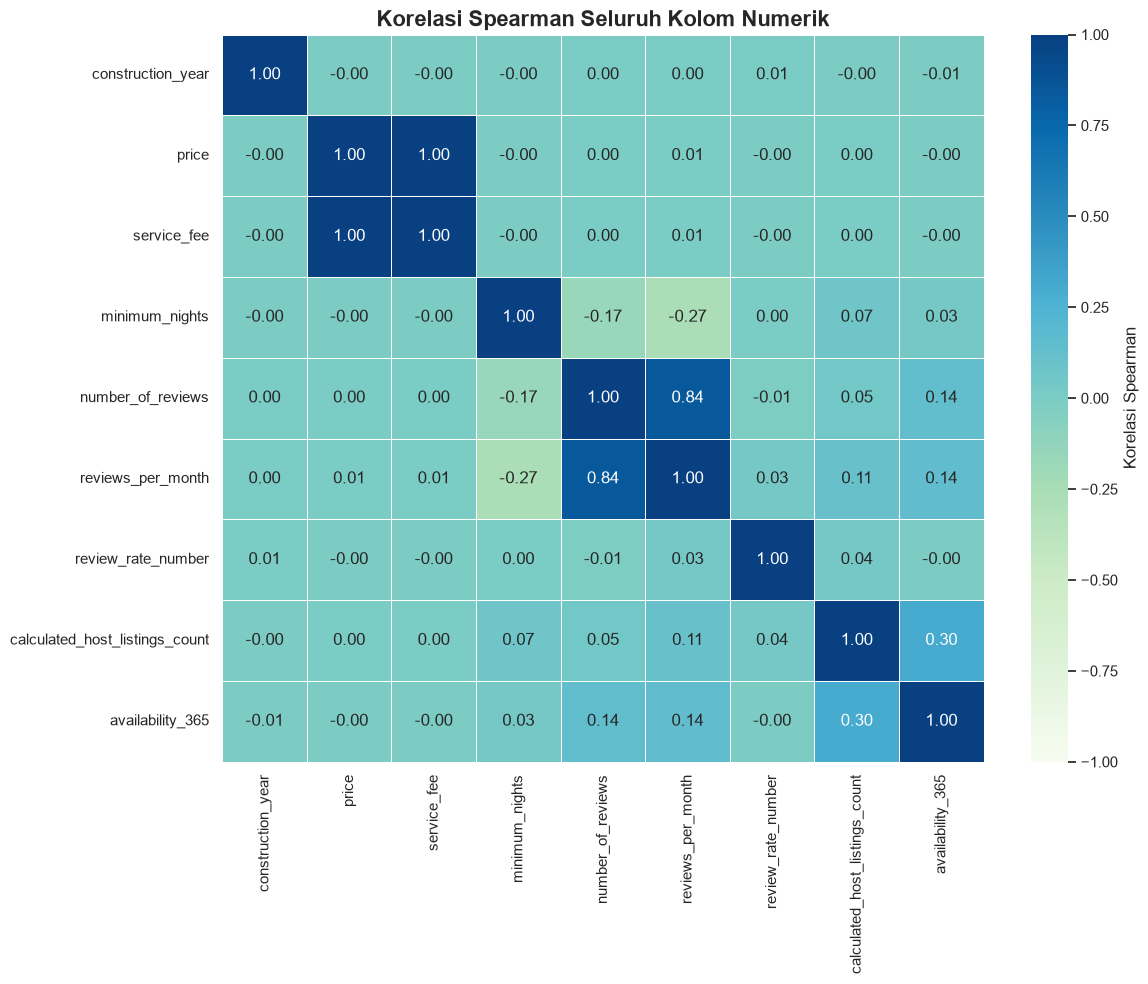

In [4]:
corr = df[NUM_COLS].corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="GnBu", vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={"label": "Korelasi Spearman"})
plt.title("Korelasi Spearman Seluruh Kolom Numerik", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "02_heatmap_spearman.png"), dpi=150, bbox_inches="tight")
plt.show()

In [5]:
pasangan = {
    "price vs service_fee": ("price", "service_fee"),
    "number_of_reviews vs reviews_per_month": ("number_of_reviews", "reviews_per_month"),
    "minimum_nights vs reviews_per_month": ("minimum_nights", "reviews_per_month"),
    "review_rate_number vs price": ("review_rate_number", "price"),
}
for nama, (a, b) in pasangan.items():
    print(f"{nama}: {corr.loc[a, b]:.2f}")

price vs service_fee: 1.00
number_of_reviews vs reviews_per_month: 0.84
minimum_nights vs reviews_per_month: -0.27
review_rate_number vs price: -0.00


**Temuan:**
- `price` dan `service_fee` berkorelasi 1,00: biaya layanan adalah persentase tetap dari harga, tanpa komponen tersembunyi.
- `number_of_reviews` dan `reviews_per_month` berkorelasi tinggi: listing yang populer secara historis juga konsisten menarik tamu baru tiap bulan.
- `minimum_nights` berkorelasi negatif dengan `reviews_per_month`: syarat menginap yang lebih lama membuat perputaran tamu lebih lambat.
- `review_rate_number` hampir tidak berkorelasi dengan `price`: harga mahal tidak menjamin rating tinggi.

## 4. Korelasi antar kolom kategori (Cramér's V)

Cramér's V (0 sampai 1) mengukur kekuatan keterkaitan dua kolom kategori. Versi yang dipakai sudah dikoreksi bias supaya tidak membengkak pada kolom dengan banyak kategori.

In [6]:
def cramers_v(x, y):
    tabel = pd.crosstab(x, y)
    chi2 = ss.chi2_contingency(tabel)[0]
    n = tabel.sum().sum()
    phi2 = chi2 / n
    r, k = tabel.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    if min(kcorr - 1, rcorr - 1) == 0:
        return 0.0
    return float(np.sqrt(phi2corr / min(kcorr - 1, rcorr - 1)))


# "Not Specified" dan "Unknown" adalah penanda nilai kosong, bukan kategori sungguhan;
# bila ikut dihitung, 76 baris yang kosong di dua kolom sekaligus membuat keterkaitannya tampak kuat
PENANDA_KOSONG = ["Not Specified", "Unknown"]
df_cat = df[CAT_COLS].replace(PENANDA_KOSONG, np.nan).dropna()

cramer = pd.DataFrame(index=CAT_COLS, columns=CAT_COLS, dtype=float)
for c1 in CAT_COLS:
    for c2 in CAT_COLS:
        cramer.loc[c1, c2] = cramers_v(df_cat[c1], df_cat[c2])

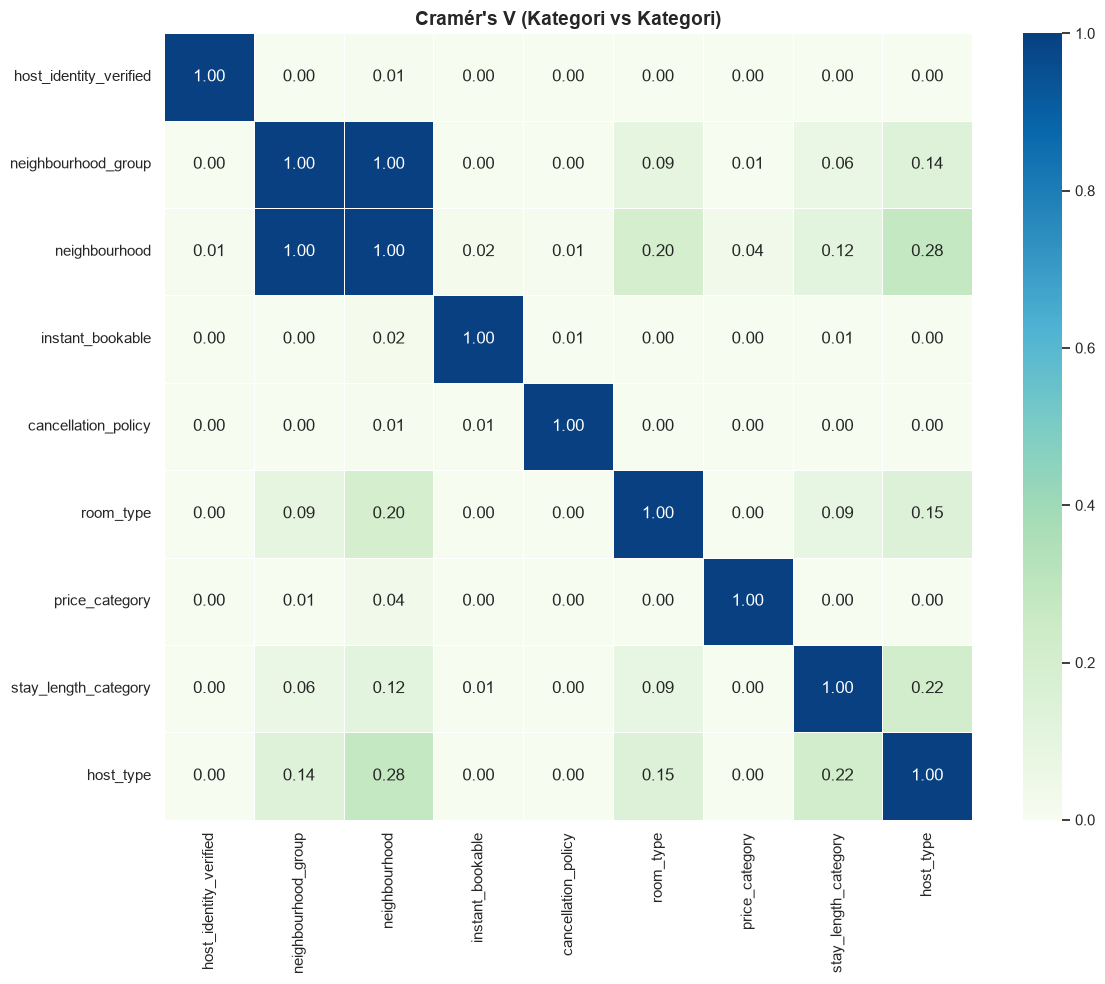

instant_bookable vs cancellation_policy: 0.01
neighbourhood_group vs neighbourhood: 1.0


In [7]:
plt.figure(figsize=(12, 10))
sns.heatmap(cramer, annot=True, fmt=".2f", cmap="GnBu", vmin=0, vmax=1, linewidths=0.5)
plt.title("Cramér's V (Kategori vs Kategori)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "03_heatmap_cramers_v.png"), dpi=150, bbox_inches="tight")
plt.show()

print("instant_bookable vs cancellation_policy:", round(cramer.loc["instant_bookable", "cancellation_policy"], 2))
print("neighbourhood_group vs neighbourhood:", round(cramer.loc["neighbourhood_group", "neighbourhood"], 2))

**Temuan:**
- `instant_bookable` dan `cancellation_policy` hampir tidak berkaitan. Pada tiap kebijakan pembatalan, sekitar sepertiga listing memakai instant booking dan dua pertiganya tidak. Keterkaitan yang tampak kuat bila penanda `Not Specified` ikut dihitung hanyalah artefak dari segelintir baris yang kosong di kedua kolom sekaligus.
- `neighbourhood_group` dan `neighbourhood` terkait sangat kuat, tetapi itu murni karena secara geografis satu lingkungan selalu berada di satu wilayah besar yang sama.

## 5. Korelasi kategori vs numerik (Correlation Ratio)

Correlation ratio (0 sampai 1) mengukur seberapa besar sebuah kategori menjelaskan variasi sebuah angka.

In [8]:
def correlation_ratio(kategori, nilai):
    nilai = nilai.astype(float)
    rata_total = nilai.mean()
    grup = nilai.groupby(kategori.values)
    numerator = (grup.size() * (grup.mean() - rata_total) ** 2).sum()
    denominator = ((nilai - rata_total) ** 2).sum()
    return 0.0 if numerator == 0 else float(np.sqrt(numerator / denominator))


df_mix = df[CAT_COLS + NUM_COLS].replace(PENANDA_KOSONG, np.nan).dropna()

ratio = pd.DataFrame(index=CAT_COLS, columns=NUM_COLS, dtype=float)
for cat in CAT_COLS:
    for num in NUM_COLS:
        ratio.loc[cat, num] = correlation_ratio(df_mix[cat], df_mix[num])

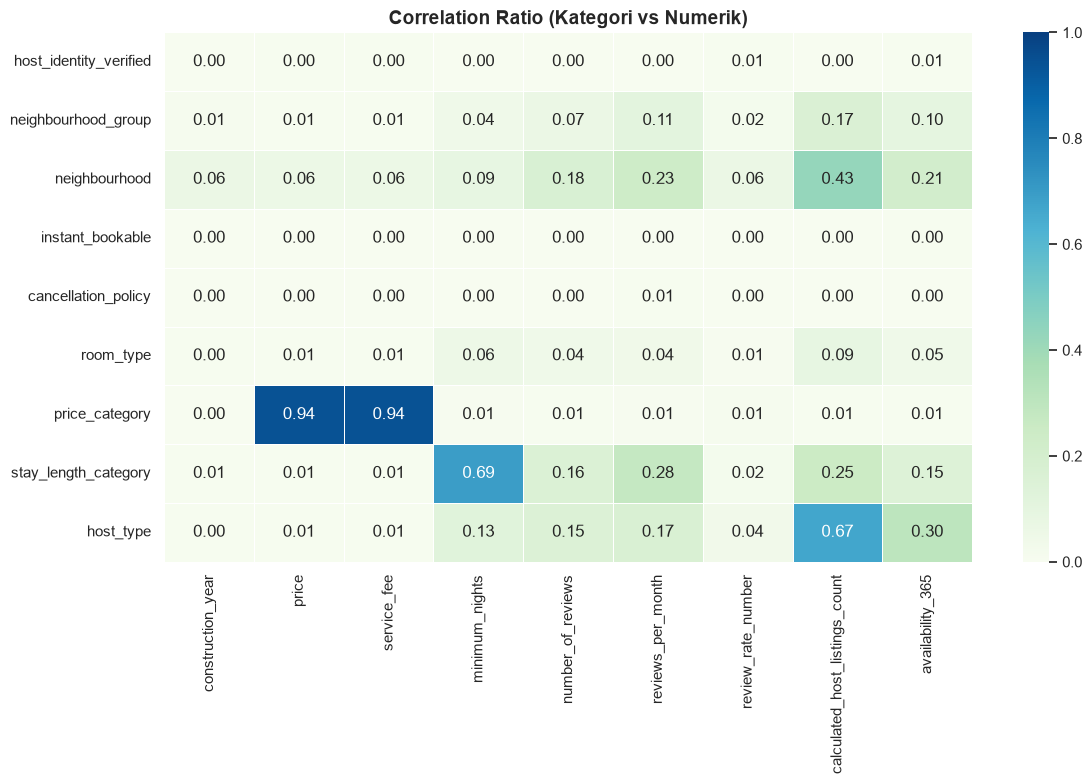

neighbourhood vs calculated_host_listings_count: 0.43
host_type vs availability_365: 0.3


In [9]:
plt.figure(figsize=(12, 8))
sns.heatmap(ratio, annot=True, fmt=".2f", cmap="GnBu", vmin=0, vmax=1, linewidths=0.5)
plt.title("Correlation Ratio (Kategori vs Numerik)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "04_heatmap_correlation_ratio.png"), dpi=150, bbox_inches="tight")
plt.show()

print("neighbourhood vs calculated_host_listings_count:", round(ratio.loc["neighbourhood", "calculated_host_listings_count"], 2))
print("host_type vs availability_365:", round(ratio.loc["host_type", "availability_365"], 2))

**Temuan:**
- `neighbourhood` dan `calculated_host_listings_count` terkait cukup kuat: host berskala besar memusatkan properti di area tertentu, bukan menyebarkannya secara acak.
- `host_type` dan `availability_365` terkait: host berskala besar cenderung membuka kalender hampir sepanjang tahun karena propertinya murni untuk disewakan, sedangkan host individu lebih sering memblokir tanggal.

## 6. Menjawab pertanyaan bisnis

Metrik yang dipakai: **reviews_per_month** sebagai ukuran aktivitas atau demand per listing, **number_of_reviews** sebagai total permintaan historis, dan **review_rate_number** sebagai rating tamu.

> Catatan: nilai `reviews_per_month` dan `number_of_reviews` yang kosong pada data mentah sudah diisi 0 di notebook 01 (listing tanpa review), sehingga rata-rata di bawah memasukkan listing yang belum punya review.

### Pertanyaan 1: Instant booking dan kebijakan pembatalan

In [10]:
q1 = (df[df["instant_bookable"].isin(["True", "False"]) & df["cancellation_policy"].isin(["strict", "moderate", "flexible"])]
      .pivot_table(index="cancellation_policy", columns="instant_bookable",
                   values="reviews_per_month", aggfunc="mean")
      .round(2)
      .loc[["flexible", "moderate", "strict"]])
q1["selisih (True - False)"] = (q1["True"] - q1["False"]).round(2)
q1

instant_bookable,False,True,selisih (True - False)
cancellation_policy,,,
flexible,1.16,1.18,0.02
moderate,1.16,1.17,0.01
strict,1.15,1.14,-0.01


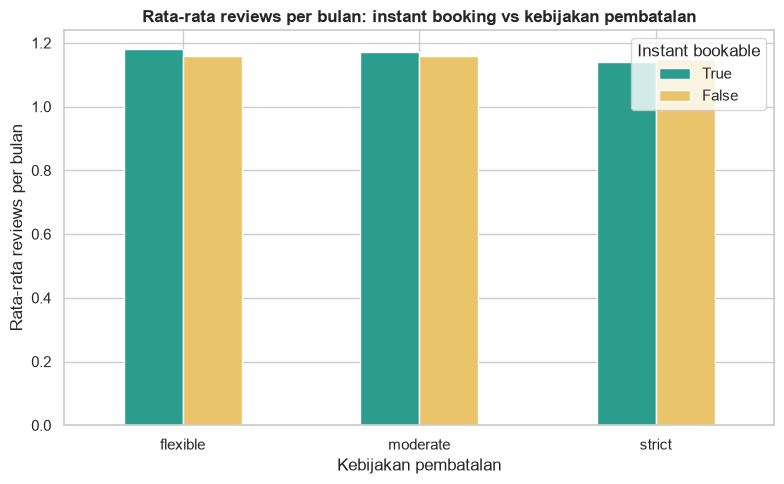

In [11]:
ax = q1[["True", "False"]].plot(kind="bar", figsize=(8, 5), color=["#2a9d8f", "#e9c46a"], rot=0)
ax.set_title("Rata-rata reviews per bulan: instant booking vs kebijakan pembatalan", fontweight="bold")
ax.set_xlabel("Kebijakan pembatalan")
ax.set_ylabel("Rata-rata reviews per bulan")
ax.legend(title="Instant bookable")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "05_instant_booking.png"), dpi=150, bbox_inches="tight")
plt.show()

**Temuan:** selisih rata-rata review per bulan antara listing dengan dan tanpa instant booking hanya 0,01 sampai 0,02 di semua kebijakan pembatalan (flexible 1,18 vs 1,16; moderate 1,17 vs 1,16; strict 1,14 vs 1,15). Instant booking bukan faktor penentu aktivitas review.

### Pertanyaan 2: Harga dan demand per wilayah

In [12]:
q2 = (df[df["neighbourhood_group"] != "Unknown"]
      .groupby("neighbourhood_group")
      .agg(listing=("id", "size"),
           rata_rata_harga=("price", "mean"),
           total_review=("number_of_reviews", "sum"),
           review_per_listing=("number_of_reviews", "mean"),
           reviews_per_month=("reviews_per_month", "mean"))
      .round(2)
      .sort_values("total_review", ascending=False))
q2

,listing,rata_rata_harga,total_review,review_per_listing,reviews_per_month
neighbourhood_group,,,,,
Brooklyn,41627,626.55,1186529,28.50,1.13
Manhattan,43551,622.74,1050150,24.11,1.04
Queens,13195,630.28,443949,33.65,1.59
Bronx,2694,627.76,85510,31.74,1.52
Staten Island,949,623.99,33971,35.80,1.54


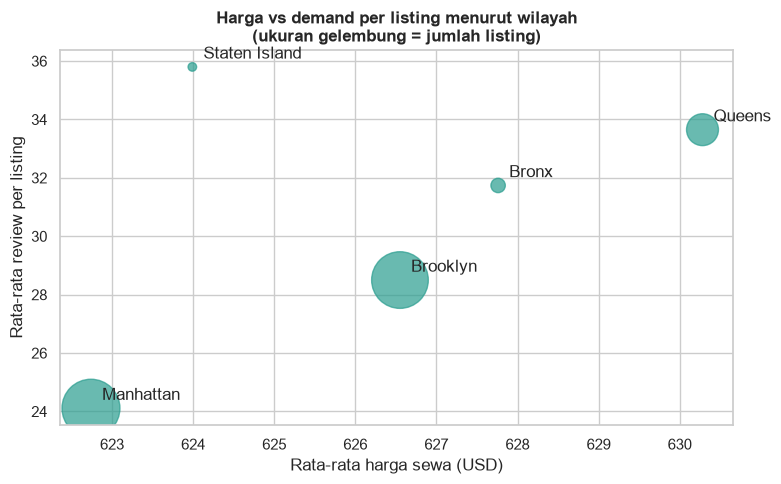

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(q2["rata_rata_harga"], q2["review_per_listing"], s=q2["listing"] / 25,
           color="#2a9d8f", alpha=0.7)
for wilayah, baris in q2.iterrows():
    ax.annotate(wilayah, (baris["rata_rata_harga"], baris["review_per_listing"]),
                textcoords="offset points", xytext=(8, 6))
ax.set_title("Harga vs demand per listing menurut wilayah\n(ukuran gelembung = jumlah listing)", fontweight="bold")
ax.set_xlabel("Rata-rata harga sewa (USD)")
ax.set_ylabel("Rata-rata review per listing")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "06_harga_demand_wilayah.png"), dpi=150, bbox_inches="tight")
plt.show()

**Temuan:**
- Rata-rata harga hampir sama di semua wilayah ($623 sampai $630, selisih sekitar 1,2%), jadi harga bukan pembeda antar wilayah.
- Manhattan (43.551 listing) dan Brooklyn (41.627) memiliki listing terbanyak dan otomatis total review terbesar, tetapi demand **per listing** justru terendah: 24,1 dan 28,5 review per listing.
- Queens (13.195 listing) memiliki rata-rata harga tertinggi ($630), namun demand per listing lebih tinggi: 33,6 review per listing dan 1,59 review per bulan, dibandingkan 1,04 di Manhattan.
- Jumlah listing bukan ukuran demand. Wilayah dengan listing sedikit tetapi review per listing tinggi (Queens, Bronx, Staten Island) menunjukkan permintaan yang belum sepenuhnya terlayani, dan menjadi kandidat ekspansi host baru.

### Pertanyaan 3: Rating dan verifikasi host

In [14]:
q3 = (df[df["host_identity_verified"].isin(["verified", "unconfirmed"])]
      .groupby("host_identity_verified")["review_rate_number"]
      .value_counts(normalize=True)
      .unstack()
      .mul(100).round(1))
print("Persentase tiap rating dalam kelompoknya (%)")
print(q3)

rata = df.groupby("host_identity_verified")["review_rate_number"].mean().round(3)
print("\nRata-rata rating:")
print(rata)

Persentase tiap rating dalam kelompoknya (%)
review_rate_number        1     2     3     4     5
host_identity_verified                             
unconfirmed             9.1  22.5  23.1  22.7  22.6
verified                8.9  22.5  22.9  22.7  23.0

Rata-rata rating:
host_identity_verified
unconfirmed    3.271
verified       3.285
Name: review_rate_number, dtype: float64


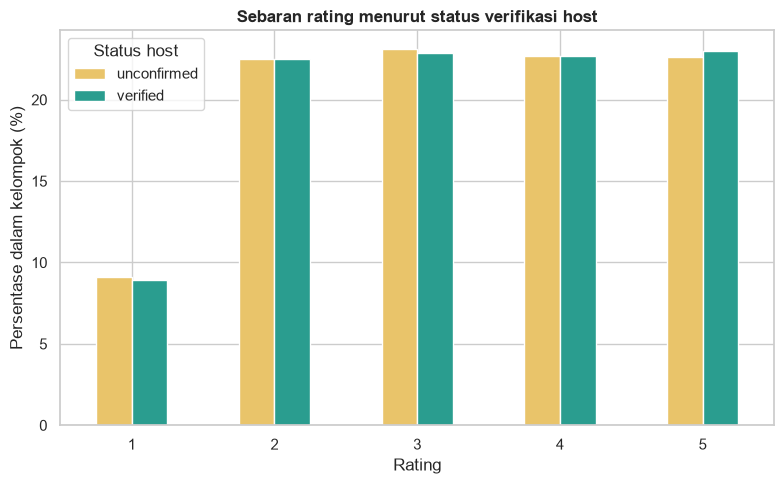

In [15]:
ax = q3.T.plot(kind="bar", figsize=(8, 5), color=["#e9c46a", "#2a9d8f"], rot=0)
ax.set_title("Sebaran rating menurut status verifikasi host", fontweight="bold")
ax.set_xlabel("Rating")
ax.set_ylabel("Persentase dalam kelompok (%)")
ax.legend(title="Status host")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "07_rating_verifikasi.png"), dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# uji formal: apakah status verifikasi berkaitan dengan rating?
tabel = pd.crosstab(df["host_identity_verified"], df["review_rate_number"])
chi2, p, _, _ = ss.chi2_contingency(tabel)
print(f"chi-square = {chi2:.2f}, p-value = {p:.3f}, Cramér's V = {cramers_v(df['host_identity_verified'], df['review_rate_number']):.3f}")

chi-square = 4.97, p-value = 0.290, Cramér's V = 0.003


**Temuan:** sebaran rating host terverifikasi dan belum terverifikasi hampir identik (misalnya rating 5: 23,0% vs 22,6%), dengan rata-rata 3,29 vs 3,27. Uji chi-square tidak signifikan (p = 0,290; Cramér's V = 0,003). Status verifikasi tidak berkaitan dengan rating, jadi label itu tidak bisa dipakai sebagai indikator kualitas.

### Pertanyaan 4: Skala bisnis host

In [17]:
q4 = (df.groupby("host_type", observed=True)
        .agg(listing=("id", "size"),
             reviews_per_month=("reviews_per_month", "mean"),
             rating=("review_rate_number", "mean"))
        .round(2)
        .loc[["Single Host", "Dual Host", "Multi Host", "Enterprise"]])
q4

,listing,reviews_per_month,rating
host_type,,,
Single Host,63431,1.01,3.24
Dual Host,14380,1.46,3.30
Multi Host,16503,1.68,3.35
Enterprise,7731,0.74,3.37


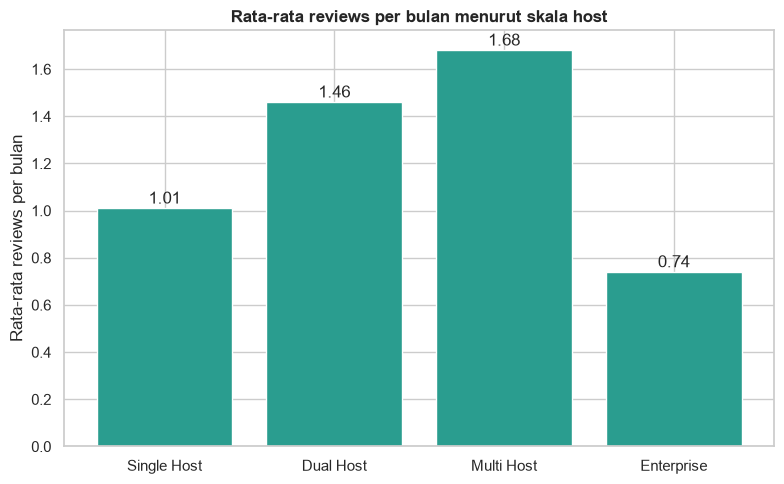

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(q4.index, q4["reviews_per_month"], color="#2a9d8f")
for i, v in enumerate(q4["reviews_per_month"]):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center")
ax.set_title("Rata-rata reviews per bulan menurut skala host", fontweight="bold")
ax.set_ylabel("Rata-rata reviews per bulan")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "08_skala_host.png"), dpi=150, bbox_inches="tight")
plt.show()

**Temuan:**
- Rating hampir sama di semua skala host (3,24 sampai 3,37).
- Aktivitas review membentuk pola huruf U terbalik: Single Host 1,01, Dual Host 1,46, Multi Host 1,68, lalu turun tajam pada Enterprise (0,74).
- Jadi host dengan banyak properti tidak otomatis lebih aktif: host skala menengah (Dual dan Multi) paling aktif, sedangkan host berskala besar (Enterprise) paling rendah. Penurunan itu hanya terjadi pada Enterprise, bukan pada semua host yang punya lebih dari satu properti.